# Introduction: Backward Sensitivities (Adjoint/VJP) in AIFS with Anemoi Inference

This notebook demonstrates how to use the Anemoi inference framework to analyze the sensitivity of AIFS to changes in its input values, focusing on backward sensitivities—also known as adjoint or vector-Jacobian product (VJP) analysis.

**What are backward sensitivities?**
Backward sensitivities answer questions like:
*"What would a 1K perturbation in the t2m (2-meter temperature) forecast for day-10 around Reading trace back to in the current atmospheric conditions, up to first order?"*

This analysis computes how a small change in a future forecast (e.g., temperature at a specific location and time) can be traced back to the present atmospheric state. This is crucial for understanding which current features most influence future predictions and for model validation and improvement.

**How does the perturbation work?**
The perturbation created in this notebook applies a change to all data points within a specified radius around a chosen location. This allows us to study the spatial impact of localized changes and how they propagate backward through the model.

**What will you learn?**
By visualizing these sensitivities, we gain insight into the regions and variables in the current state that most affect the forecast at the target location and time. We will use the `anemoi.inference.runners.sensitivities.SensitivitiesRunner` to compute sensitivities and explore how different input perturbations influence the forecast results.

AIFS leverages machine learning and numerical weather prediction data to provide advanced forecasts. Sensitivity analysis helps us understand how variations in input parameters affect the model's outputs, which is crucial for model validation and improvement.

## Setup your environment

This notebook should work with the environment you used to train the model this week. If you wanted to use a different checkpoint, ou can get the pinned requirements of the checkpoint with the `anemoi-inference` CLI.

   ```bash
   anemoi-inference inspect inference-aifs-crps-o96.ckpt --requirements > requirements.txt
   ```

   ```bash
   uv pip install -r requirements_notebook.txt anemoi-inference earthkit-data earthkit-regrid ecmwf-opendata cartopy ipykernel
   ```

Make the environment available as a Jupyter kernel and select the `aifs-explain` kernel for this notebook:

   ```bash
   python -m ipykernel install --user --name aifs-explain --display-name aifs-explain
   ```

Place the checkpoint `inference-aifs-crps-o96.ckpt` in the same folder as this notebook.

In [1]:
## Download the checkpoint

!wget https://object-store.os-api.cci1.ecmwf.int/ml-tests/test-data/samples/training-course/inference-aifs-crps-o96.ckpt

--2026-11-19 15:24:59--  https://object-store.os-api.cci1.ecmwf.int/ml-tests/test-data/samples/training-course/inference-aifs-crps-o96.ckpt
Resolving object-store.os-api.cci1.ecmwf.int (object-store.os-api.cci1.ecmwf.int)... 136.156.128.3
Connecting to object-store.os-api.cci1.ecmwf.int (object-store.os-api.cci1.ecmwf.int)|136.156.128.3|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 1008202537 (961M) [application/octet-stream]
Saving to: ‘inference-aifs-crps-o96.ckpt’

inference-aifs-crps 100%[===================>] 961.50M   154MB/s    in 6.3s    

2026-11-19 15:25:05 (153 MB/s) - ‘inference-aifs-crps-o96.ckpt’ saved [1008202537/1008202537]



In [ ]:
from helpers import load_ckpt

ckpt = load_ckpt("inference-aifs-crps-o96.ckpt")  # local o96 AIFS-CRPS checkpoint
# ckpt = "FILL/WITH/THE/PATH/TO/YOUR/CKPT_FILE"

print(ckpt)

/home/ecm1922/Projects_hpcperm/ml-training-course/2026-ml-training/.venv/lib/python3.12/site-packages/torch/cuda/__init__.py:61: FutureWarning: The pynvml package is deprecated. Please install nvidia-ml-py instead. If you did not install pynvml directly, please report this to the maintainers of the package that installed pynvml for you.
  import pynvml  # type: ignore[import]


In [3]:
# !anemoi-inference inspect inference-aifs-crps-o96.ckpt --requirements
# !anemoi-inference inspect inference-aifs-crps-o96.ckpt --variables

### About this checkpoint (AIFS-CRPS, o96)

This is the ensemble model **AIFS-CRPS** (trained with a CRPS loss) on the ~1° `o96` grid (40320 grid points). Compared with the deterministic AIFS it has far fewer variables:

- **Prognostic** (input and output): `2t`, `tcw`, `t_850`, `z_1000`, `z_700`, `z_500`, `z_300`, `z_250`
- **Diagnostic** (output only): `cp`, `tp`
- **Forcings** (input only): `lsm`, `z` (surface geopotential), `slor`, `sdor` and the computed `cos/sin_latitude`, `cos/sin_longitude`, `cos/sin_julian_day`, `cos/sin_local_time`, `insolation`

Two things to be aware of:

1. **Metadata patch.** The metadata of this checkpoint is inconsistent with the model (it lists 13 input steps, whereas the model was trained with 2 input steps, `t-6h` and `t`). We therefore pass `PATCH_METADATA` (defined in `helpers.py`) when loading the checkpoint.
2. **Noise.** The model injects random noise in its processor, so the sensitivities are those of a single ensemble member. We fix a seed to make them reproducible; change it to explore the spread between members.

## Step-by-Step Sensitivity Analysis Workflow

1. **Import Libraries and Modules**
   
Load required Python libraries and Anemoi modules for sensitivity analysis and plotting.



In [ ]:
import logging
import torch
import os
import warnings
from typing import Any
from ecmwf.opendata import Client as OpendataClient

from anemoi.inference.outputs.printer import print_state
from perturbation import Perturbation
from sensitivities import SensitivitiesRunner

from helpers import load_input_state
from helpers import load_ckpt
from helpers import PATCH_METADATA
from helpers import haversine
from helpers import compute_sensitivities_statistics
from plotting import plot_sensitivities
from plotting import plot_summary_sfc
from plotting import plot_summary_pl
from plotting import plot_cross_section

os.environ['PYTORCH_CUDA_ALLOC_CONF'] = 'expandable_segments:True'
os.environ['ANEMOI_INFERENCE_NUM_CHUNKS'] = '16'

warnings.filterwarnings('ignore')

LOGGER = logging.getLogger(__name__)

assert torch.cuda.is_available(), "CUDA is not available. Please check your GPU setup."

2. **Set Up Experiment Date and Model Checkpoint**

Select the forecast date and specify the model checkpoint to use for inference. We recommend an "o96" model (~1 deg) to make sure the model fits into 1 GPU.


In [5]:
DATE = OpendataClient().latest()
# import datetime
# DATE = datetime.datetime(2025, 11, 15, 6, 0)

To ensure the stability of our systems and to preserve resources for our operational activities (network, compute, etc.), access to the open-data portal is limited to 500 simultaneous connections. This limit helps us guarantee reliable service for our operational users, especially during periods of high demand. For added reliability, the open-data is replicated across AWS, Azure, and Google Cloud. If you experience difficulties accessing the portal directly, you can also retrieve the data from these cloud platforms.


3. **Load Initial Atmospheric State**

Retrieve the input state for the selected date using helper functions.
- Print the loaded state for inspection.

In [6]:
# Load initial conditions
input_state = load_input_state(DATE, resolution="O96")
print_state(input_state)


<multiple>:   0%|          | 0.00/2.77M [00:00<?, ?B/s]


<multiple>:   0%|          | 14.1k/2.77M [00:00<00:22, 126kB/s]


<multiple>:  30%|███       | 854k/2.77M [00:00<00:00, 4.22MB/s]

By downloading data from the ECMWF open data dataset, you agree to the terms: Attribution 4.0 International (CC BY 4.0). Please attribute ECMWF when downloading this data.



<multiple>:   0%|          | 0.00/2.78M [00:00<?, ?B/s]


<multiple>:  30%|███       | 858k/2.78M [00:00<00:00, 8.34MB/s]

... (2 outputs left out)


<multiple>:   0%|          | 0.00/2.21M [00:00<?, ?B/s]


<multiple>:  81%|████████  | 1.78M/2.21M [00:00<00:00, 17.5MB/s]


<multiple>:   0%|          | 0.00/2.20M [00:00<?, ?B/s]

😀 date=2026-11-16T12:00:00 fields=12

    2t     shape=(2, 40320) min=230.454        max=315.064       
    tcw    shape=(2, 40320) min=0.177446       max=90.9972       
    lsm    shape=(2, 40320) min=0              max=1             
    z      shape=(2, 40320) min=-1361.22       max=54732.4       



4. **Initialize Sensitivity Runner**

Create a `SensitivitiesRunner` instance with the chosen checkpoint and device (GPU).

In [7]:
# Create runner
runner = SensitivitiesRunner(
    ckpt, 
    device="cuda",
    perturb_normalised_space=True,
    return_unnormalised_sensitivities=False,
    patch_metadata=PATCH_METADATA,
    seed=42,  # the model is an ensemble model: fix the noise to get reproducible sensitivities
)

[data] Patching metadata with DotDict({'metadata_inference': DotDict({'data': DotDict({'timesteps': DotDict({'input_relative_date_indices': [0, 1], 'output_relative_date_indices': [2]})})})})


[data] Constant forcings are not supported by this runner.


[data] ['lsm', 'sdor', 'slor', 'z'] must be provided in the input state by the user.


5. **Define Perturbation**

The class `LocalPerturbation` is used here to create a local perturbation, but this class can be extended to implement other types of perturbations as needed for different experiments.
- Specify the variable to perturb (e.g., 2-meter temperature), location (latitude, longitude), and radius (km) for the perturbation.
- The perturbation will affect all data points within the defined radius.
- This perturbation adds 1 in the normalised spaced of the target.
- With `normalise=True`, the perturbation is `1/N` on each of the `N` points in the radius, so that the target is the *mean* of the variable over the region (instead of the sum). This is useful to read the sensitivities as "K per unit of input".

In [8]:
class LocalPerturbation(Perturbation):
    """Perturbation class."""

    def __init__(
        self,
        checkpoint: str,
        perturbed_variable: str,
        perturbation_location: float,
        perturbation_radius_km: float = 100.0,
        normalise: bool = False,
        patch_metadata: dict[str, Any] = {},
    ) -> None:
        super().__init__(checkpoint, patch_metadata=patch_metadata)

        assert len(perturbation_location) == 2, "perturbation_location must be a tuple of (lat, lon)"
        assert perturbation_location[0] >= -90 and perturbation_location[0] <= 90, "Latitude must be between -90 and 90"
        assert perturbation_location[1] >= 0 and perturbation_location[1] <= 360, "Longitude must be between 0 and 360"

        self.perturbed_variable = perturbed_variable
        self.perturbation_location = torch.tensor(perturbation_location)
        self.perturbation_radius_km = perturbation_radius_km
        self.normalise = normalise

        # Indices of the grid points within the radius of the location
        dists = haversine(self.coords, self.perturbation_location)
        self.region_indices = torch.where(dists < self.perturbation_radius_km)[0]
        assert len(self.region_indices) > 0, "No grid points found within the specified perturbation radius."

    def create(self, *args, **kwargs) -> torch.Tensor:
        """Get the perturbation data."""
        var_idx = self.variable_to_output_tensor_index[self.perturbed_variable]
        perturbation = torch.zeros(self.output_shape)

        # If normalise=True the perturbation is 1/N on each of the N points, so that the target of the
        # sensitivities is the *mean* of the variable over the region (instead of the sum).
        value = 1.0 / len(self.region_indices) if self.normalise else 1.0
        perturbation[..., self.region_indices, var_idx] = value
        return perturbation

In [9]:
perturbation = LocalPerturbation(
    ckpt,
    perturbed_variable="2t",
    perturbation_location=(40, 120), # (lat, lon)
    perturbation_radius_km=350.0,
    patch_metadata=PATCH_METADATA,
)

[data] Patching metadata with {'metadata_inference': {'data': {'timesteps': {'input_relative_date_indices': [0, 1], 'output_relative_date_indices': [2]}}}}



6. **Run Sensitivity Analysis**

Execute the runner to compute backward sensitivities for the given input state and perturbation.
- Only a 6-hour lead time is supported in this example.
- Print the computed sensitivities for review.

In [10]:
# Compute sensitivities
for sensitivities in runner.run(input_state=input_state, perturbation=perturbation, lead_time="6h"): # only 6h supported
    print_state(sensitivities)
    stats_df = compute_sensitivities_statistics(sensitivities)

😀 date=2026-11-16T18:00:00 latitudes=(40320,) longitudes=(40320,) fields=21

    2t             shape=(2, 40320) min=-0.412186      max=1.61572       
    tcw            shape=(2, 40320) min=-0.988113      max=0.737946      
    cos_julian_day shape=(2, 40320) min=-0.444084      max=0.789619      
    cos_latitude   shape=(2, 40320) min=-1.50098       max=0.791931      



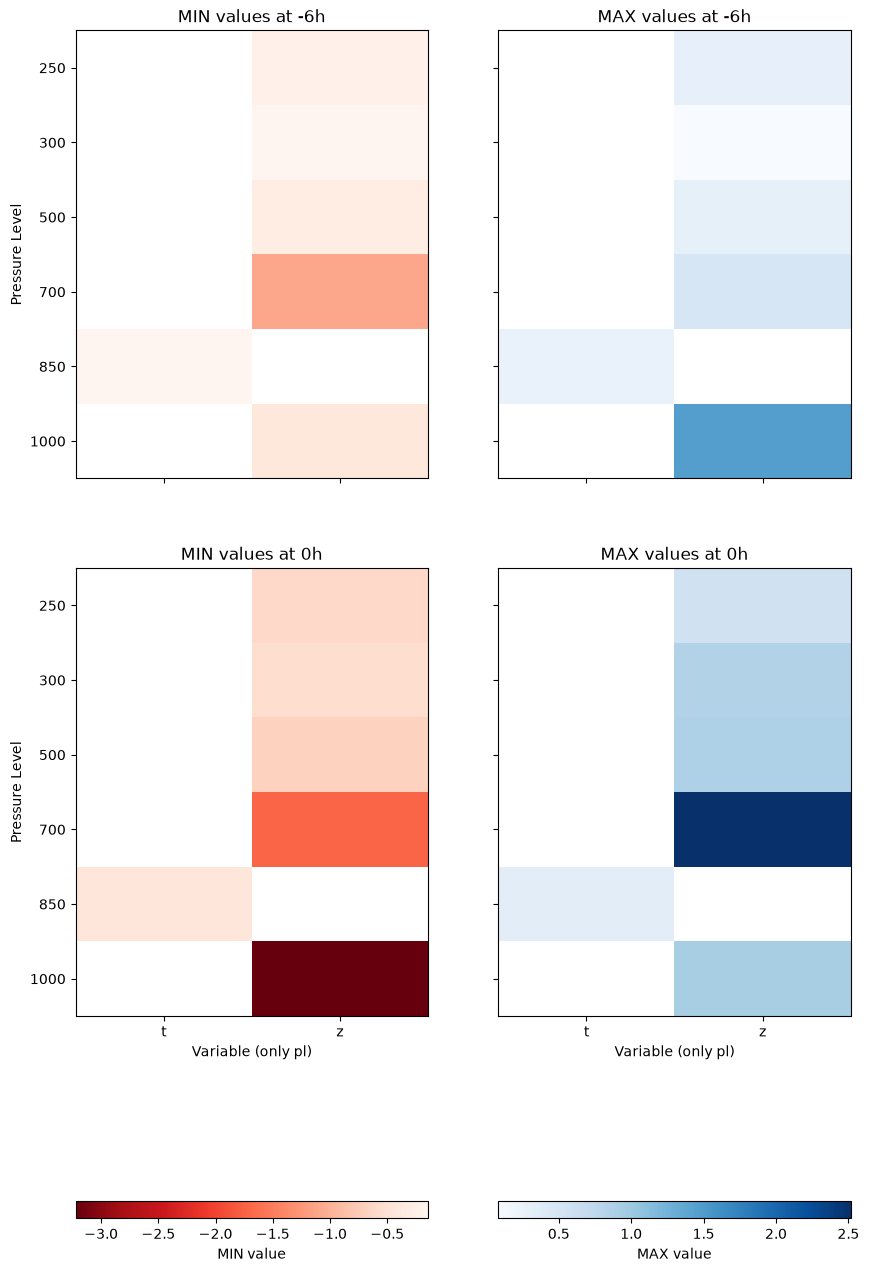

In [11]:
plot_summary_pl(stats_df, stats=["min", "max"], cmaps=dict(min="Reds_r", max="Blues"))

7. **Visualize Sensitivities**

Plot the sensitivities for the perturbed variable (e.g., "2t") to see which regions in the current state most influence the forecast.
   - Optionally, plot sensitivities for other variables (e.g., "z_500") and restrict the visualization to specific areas.

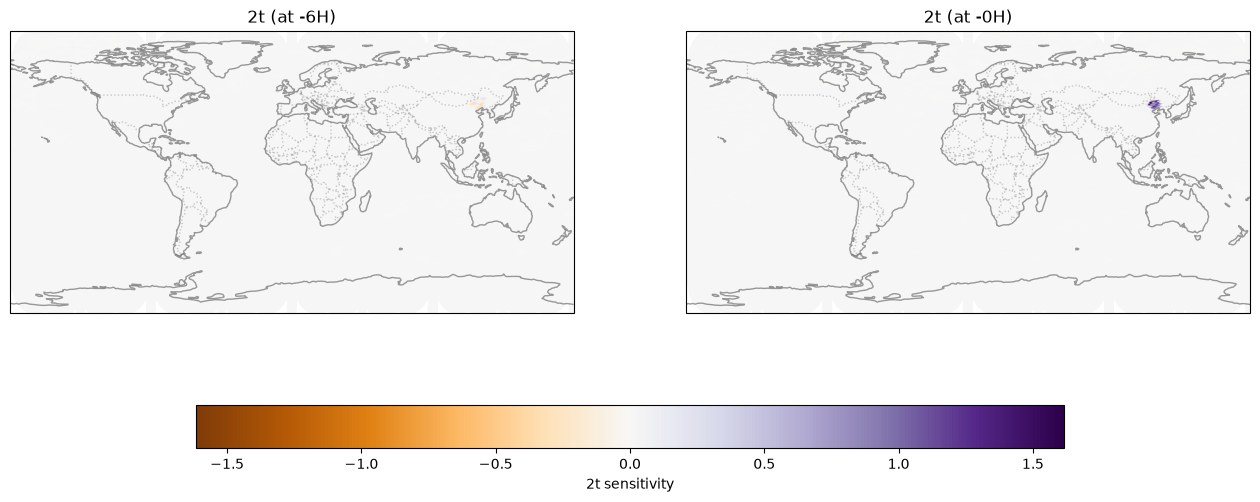

In [12]:
plot_sensitivities(sensitivities, "2t")

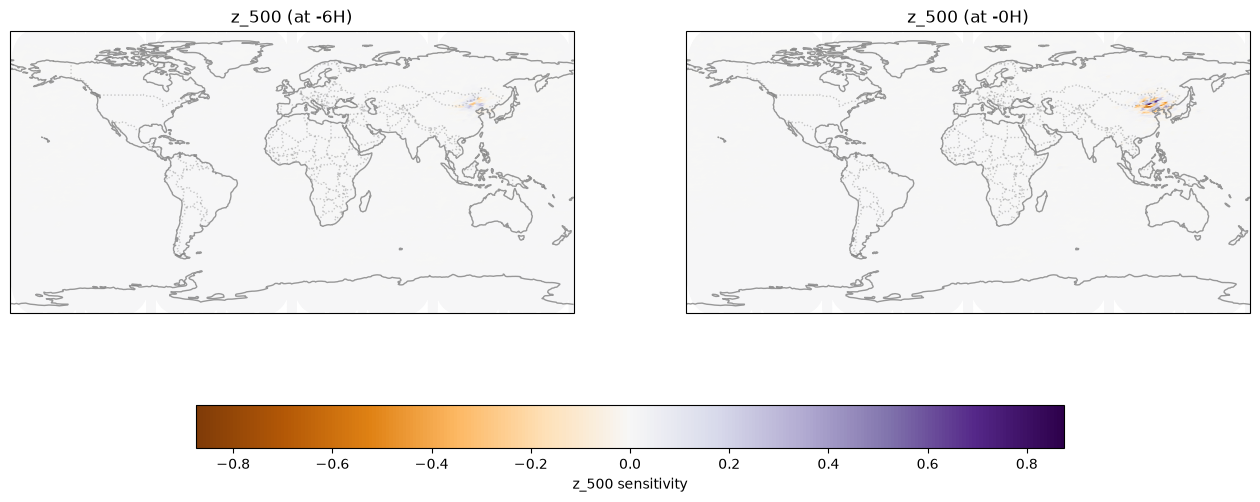

In [13]:
plot_sensitivities(sensitivities, "z_500")

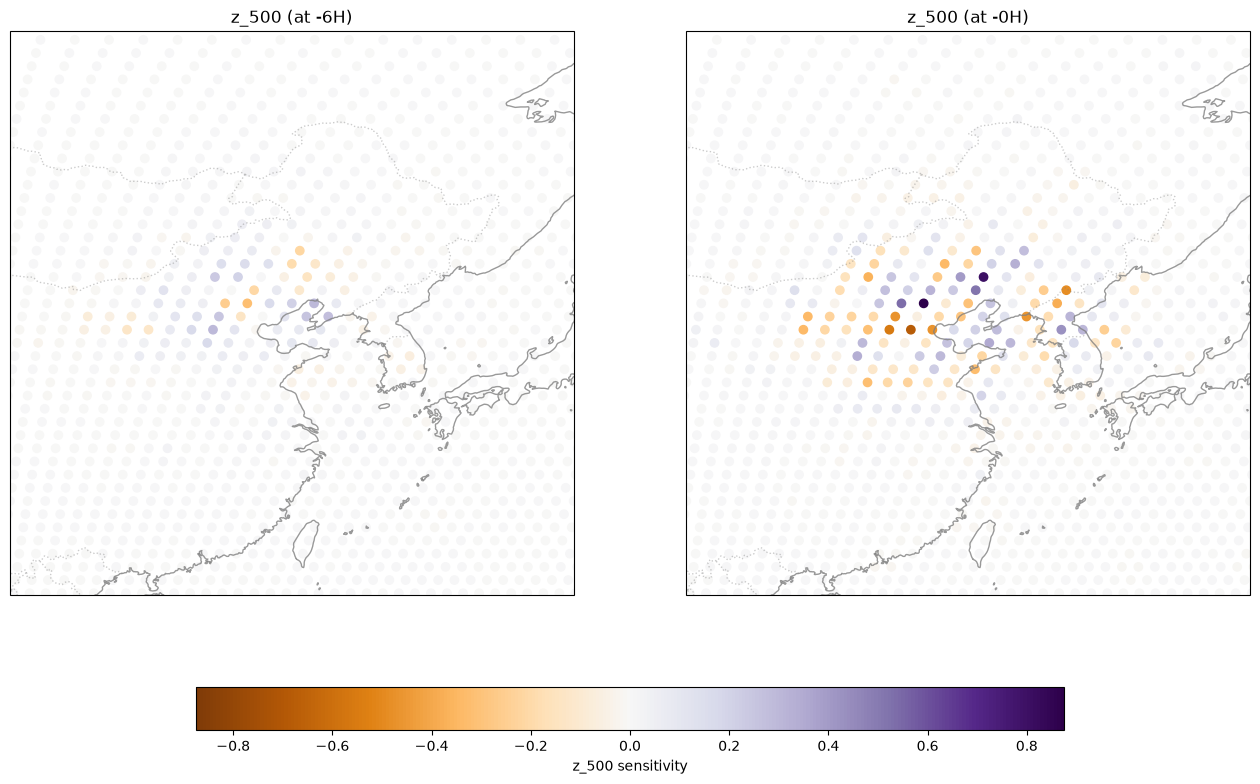

In [14]:
plot_sensitivities(sensitivities, "z_500", area=(100, 140, 20, 60))
# area=(left, right, bottom, top) = (lon_min, lon_max, lat_min, lat_max)

Plotting cross-section sensitivities at latitude=40.5° with 228 points at 5 pressure levels.


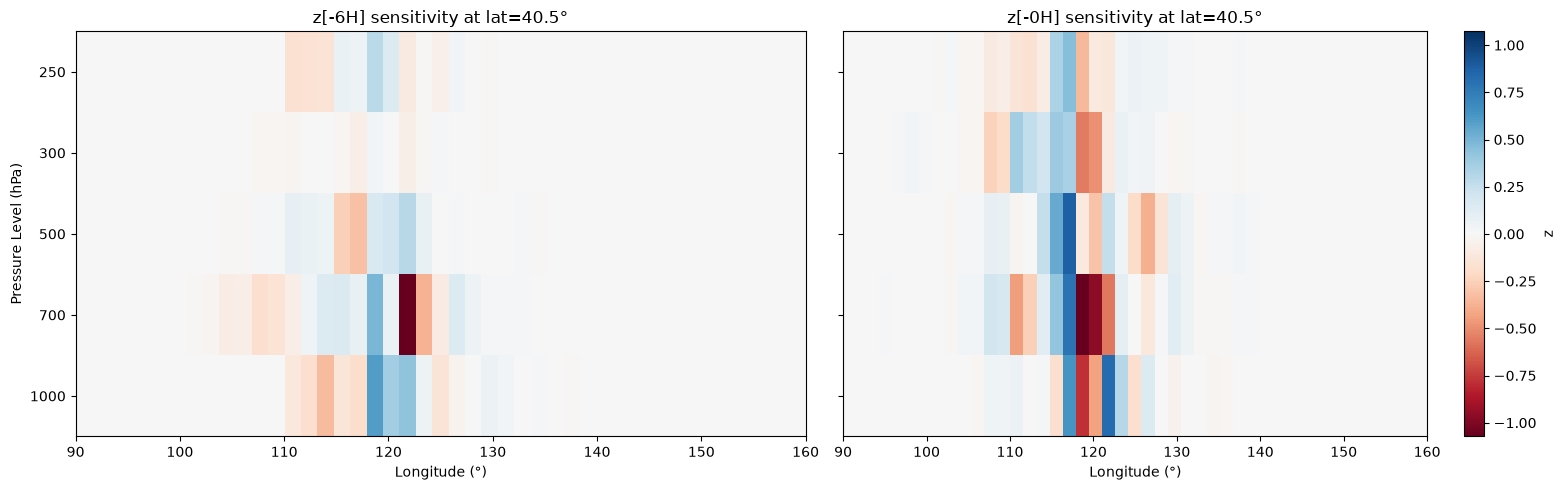

In [15]:
plot_cross_section("z", sensitivities, latitude=40.5, xlim=(90, 160))

### Task 5.1: Plot the sensitivities for another location

Change the location to your home town and have a look at how the sensitivities differ on different pressure levels of geopotential (`z_1000` ... `z_250`) when perturbing 2t.

### Task 5.2: Change the perturbation radius

How does this effect the sensitivies?

### Task 5.3: Implement your own Perturbation

For this task, you are asked to implement your own perturbation class. Instead of using the provided Perturbation base class directly, you should create a new class that inherits from it and overrides the create() method. Your implementation can generate any kind of perturbation you choose. Be creative and explore different spatial or variable patterns. A few examples:

- Specify a variable and perturb all pressure levels.
- Apply a perturbation to a latitude/longitude strip around the globe instead of a single grid point.
- Perturb the entire field rather than one specific location.

The goal is to experiment with how different perturbation structures affect the model behaviour.

In [16]:
class MyPerturbation(Perturbation):
    """Perturbation class."""

    def __init__(
        self,
        checkpoint: str,
        *args,
        patch_metadata: dict[str, Any] = PATCH_METADATA,
        **kwargs,
    ) -> None:
        super().__init__(checkpoint, patch_metadata=patch_metadata)

        ## TODO: Save attributes

    def create(self, *args, **kwargs) -> torch.Tensor:
        """Get the perturbation data."""
        perturbation = torch.zeros(self.output_shape)

        # TODO: Create your own perturbation
        return perturbation

---
# Exercise 6: What drove the heat in London on 13 August 2026?

Summer 2026 brought a series of record-breaking heat waves to western Europe. On **13 August 2026** the UK recorded its hottest day of the year, with press reports of about 38 °C in west London (the 0.25° ECMWF analysis is smoother, with ≈ 34 °C at 12 and 18 UTC).

Your task is to use backward sensitivities to find out what, **according to AIFS-CRPS**, the London temperature at 18 UTC depended on: which **variables**, which **region** and which **input time**.

### The set-up

| | date | what |
|---|---|---|
| `hw` | 13 Aug 2026, 12 UTC | heat-wave input state (the model uses the 06 and 12 UTC fields as its two input steps). The forecast is valid at 18 UTC |
| `ref` | 19 Aug 2026, 12 UTC | reference input state: an ordinary summer day (London ≈ 21 °C at 12 UTC) |

- **Target:** the *mean* 2t over London at +6 h (51.5°N, 0.1°W, radius 150 km, i.e. 5 grid points).
- **Units:** this time we compute the sensitivities in *physical units*, i.e. the change in K of the London 2t at 18 UTC for a unit change in each input variable. Multiplying a sensitivity by the **anomaly** `hw - ref` of the input gives a first-order **contribution in K**, and the contributions add up to (approximately) the difference between the two forecasts.

> **Past dates:** the default open-data server only keeps the latest few days. For past dates use `load_input_state(date, resolution="O96", source="google")` (other archives: `"azure"`, `"aws"`; if one is down or rate limited, try another). Downloading the states takes a minute or two the first time.

### Task 6.1: Load the data and look at the anomalies

1. Load the input states `hw` and `ref`.
2. Create a `LocalPerturbation` of `2t` over London with `normalise=True`. Be careful: longitudes must be between 0 and 360.
3. Plot the anomaly `hw - ref` of `2t`, `t_850` and `z_500` over Europe, e.g. with `plot_sensitivities` (it plots any state with `fields` of shape `(2, values)`, `latitudes` and `longitudes`; use `label="anomaly"` and `area=(-30, 30, 30, 70)`). The coordinates of the grid points are in `perturbation.coords` (`[:, 0]` are latitudes and `[:, 1]` longitudes).

**Question:** How large are the anomalies close to London? What kind of weather situation do they suggest?

In [17]:
import datetime

HW_DATE = datetime.datetime(2026, 8, 13, 12)
REF_DATE = datetime.datetime(2026, 8, 19, 12)

# TODO: load the input states `hw` and `ref`

# TODO: create the London perturbation

# TODO: plot the anomalies hw - ref

### Task 6.2: Compute the sensitivities and the forecasts

1. Create a **new** `SensitivitiesRunner` that works in physical units: `return_unnormalised_sensitivities=True` and `perturb_normalised_space=False` (keep `patch_metadata=PATCH_METADATA` and `seed=42`).
2. Run it for `hw` and for `ref`, and keep the sensitivities of both. The runner also stores the forward forecast of the last run in `runner.last_prediction`, with shape `(1, 1, values, variables)` in physical units (K for 2t). The index of `2t` is `perturbation.variable_to_output_tensor_index["2t"]` and the grid points of London are `perturbation.region_indices`.

**Question:** What is the forecast 2t over London at 18 UTC for `hw` and for `ref`? Does the model reproduce the ~12 K difference between the two days (compare with the 12 UTC analysis)?

In [18]:
# TODO: create the runner

# TODO: compute the sensitivities and the forecast (mean 2t over London) for hw and ref

### Task 6.3: Attribute the forecast difference to the inputs

The sensitivity tells how the forecast changes for a small change of the input; the anomaly `hw - ref` tells how much each input differs between the two days. To first order,

$$\Delta 2t_{London} \approx \sum_{\text{variables, times, grid points}} \frac{\partial\, 2t_{London}}{\partial x} \; (x_{hw} - x_{ref})$$

1. Compute the contribution `sensitivity * (hw - ref)` of the prognostic variables (`2t`, `tcw`, `t_850`, `z_1000`, `z_700`, `z_500`, `z_300`, `z_250`) for each grid point, using the sensitivities of `hw`.
2. Sum over the grid points and plot a bar chart with the contribution of each variable, for both input times (06 and 12 UTC). Compare the total with the difference between the two forecasts.
3. Plot the cumulative contribution as a function of the distance to London (use `haversine` from `helpers`, as in `LocalPerturbation`). Also plot a map of the total contribution (sum over the variables) over Europe.

**Questions:**
- Which variables and which input time contribute the most? How much of the forecast difference is explained by the first-order approximation?
- How **local** is the answer? Within which distance is most of the contribution? What does it tell you about the choice of a 6-hour lead time?

In [19]:
# TODO: contributions per variable and per grid point

# TODO: bar chart per variable and input time

# TODO: cumulative contribution versus distance, and a map of the total contribution

### Task 6.4: Check the attribution with forward experiments

A first-order attribution can be misleading. Verify it with a direct experiment: take the `hw` input state and **replace** some of its variables by the values of `ref`. The drop of the forecast tells how much the forecast needed these variables to be hot. The forward forecast is `runner.last_prediction` after a run.

Write a function `swap(variables, mask=None)` that returns a copy of `hw` where `variables` (both input times) are replaced by those of `ref`, optionally only at the grid points selected by a boolean `mask`. Compute the forecast change for:

1. each of `2t`, `t_850`, `tcw` and for all the `z_*` levels together;
2. all the prognostic variables together (what do you expect?);
3. all the prognostic variables only **within** some distance of London (300 km, 1000 km), and only **outside** it;
4. all the prognostic variables, but only at the 12 UTC input time, or only at the 06 UTC input time.

**Questions:**
- Do the swap experiments agree with the attribution of Task 6.3 about the *where*, the *when* and the *which variables*?
- Try swapping a single geopotential level (e.g. `z_700`) and compare with all the `z_*` levels. What do you see? *Hint:* geopotential heights at different levels are linked to the temperature of the layer between them by hydrostatic balance.

In [20]:
# TODO: swap function and forecast change for each experiment

### Task 6.5: Summarise the drivers

Write 4-6 sentences answering: **what drove the London heat at 18 UTC on 13 August 2026 according to the model?** Cover the variables, the region and the input time. Then discuss what this analysis **cannot** tell you:

- the lead time is a single 6 h model step. What would you need to find where the hot air mass *came from*?
- sensitivities are properties of the **model**, learned from data correlations, and are not necessarily physical causes (for example the role of `tcw`, or of individual `z` levels).
- AIFS-CRPS injects noise: the result is for one ensemble member. **Bonus:** repeat 6.2-6.3 with a few different seeds (`runner.noise_seed = ...`). How much do the forecast and the total attribution change?